In [4]:
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

Matplotlib is building the font cache; this may take a moment.


In [15]:
sales = pd.read_csv('vendas.csv')

# The source file uses Portuguese column names
sales = sales.rename(columns={
    'id_venda': 'sale_id',
    'data_venda': 'sale_date',
    'id_cliente': 'customer_id',
    'id_produto': 'product_id',
    'produto': 'product',
    'categoria': 'category',
    'valor_venda': 'sale_value',
    'quantidade': 'quantity',
})

# Translating category labels for display
CATEGORY_EN = {
    'Periféricos': 'Peripherals',
    'Livros': 'Books',
    'Eletrônicos': 'Electronics',
    'Decoração': 'Home Decor',
    'Colecionáveis': 'Collectibles',
    'Componentes': 'Components',
    'Áudio': 'Audio',
    'Móveis': 'Furniture',
}

sales['category'] = sales['category'].map(CATEGORY_EN).fillna(sales['category'])

In [16]:
print('Shape', sales.shape)
print(sales.dtypes, '\n')
print(sales.head())

Shape (120, 8)
sale_id          int64
sale_date          str
customer_id      int64
product_id       int64
product            str
category           str
sale_value     float64
quantity         int64
dtype: object 

   sale_id   sale_date  customer_id  product_id                     product  \
0        1  2023-02-07          109           8  Livro: A Guerra dos Tronos   
1        2  2023-01-11          139           7        Headset Surround 7.1   
2        3  2023-02-16          104          17          Mousepad Gamer XXL   
3        4  2023-03-20          145          17          Mousepad Gamer XXL   
4        5  2023-02-16          134          16       Memória RAM 16GB DDR5   

      category  sale_value  quantity  
0        Books     2677.12         2  
1        Audio     1210.10         1  
2  Peripherals     2393.06         2  
3  Peripherals     3925.92         3  
4   Components     4702.89         1  


In [17]:
# Cleaning: data types, missing values and duplicates
sales['sale_date'] = pd.to_datetime(sales['sale_date'], errors='coerce')
sales['sale_value'] = pd.to_numeric(sales['sale_value'], errors='coerce')
sales['quantity'] = pd.to_numeric(sales['quantity'], errors='coerce')

# Diagnostics
print('\nMissing values per column:\n', sales.isna().sum())
print('\nFully duplicated rows:', sales.duplicated().sum())
print('Repeated sale_id:', sales['sale_id'].duplicated().sum())
print('sale_value <= 0:', (sales['sale_value'] <= 0).sum(),
      '| quantity <= 0:', (sales['quantity'] <= 0).sum())


Missing values per column:
 sale_id        0
sale_date      0
customer_id    0
product_id     0
product        0
category       0
sale_value     0
quantity       0
dtype: int64

Fully duplicated rows: 0
Repeated sale_id: 0
sale_value <= 0: 0 | quantity <= 0: 0


In [19]:
# Strategy applied : Remove invalid rows
# Revenue is a core financial metric. 
# Filling gaps with mean or median values would invent revenue that never occurred, skewing total figures and distorting performance rankings.
# Without a valid value, quantity, or timestamp, a transaction cannot be factored into revenue calculations or monthly groupings.
rows_before = len(sales)
sales = sales.drop_duplicates()
sales = sales.drop_duplicates(subset='sale_id')
sales = sales.dropna(subset=['sale_value', 'quantity', 'sale_date'])
sales = sales[(sales['sale_value'] > 0 ) & (sales['quantity'] > 0)]
print(f'\nRows before: {rows_before} | after: {len(sales)} | removed: {rows_before - len(sales)}')



Rows before: 120 | after: 120 | removed: 0


In [20]:
# Revenue column
sales['revenue'] = sales['sale_value'] * sales['quantity']

print(f'\nTotal Q1 revenue:     R$ {sales['revenue'].sum():,.2f}')
print(f'Average ticket/sale:  R$ {sales['revenue'].mean():,.2f}')
print('Units sold:', int(sales['quantity'].sum()))


Total Q1 revenue:     R$ 810,828.88
Average ticket/sale:  R$ 6,756.91
Units sold: 291


In [21]:
# Revenue by month

sales['month'] = sales['sale_date'].dt.to_period('M')
by_month = (sales.groupby('month')
              .agg(revenue=('revenue', 'sum'),
                   sales=('sale_id', 'count'),
                   units=('quantity', 'sum'))
              .reset_index())
by_month['change_%'] = by_month['revenue'].pct_change() * 100
by_month['month_name'] = by_month['month'].dt.month.map(
    {1: 'January', 2: 'February', 3: 'March'})
print('\nRevenue by month:\n',
      by_month.drop(columns='month').round(2).to_string(index=False))



Revenue by month:
   revenue  sales  units  change_% month_name
234634.61     35     82       NaN    January
282351.34     44    107     20.34   February
293842.93     41    102      4.07      March


In [23]:
# Revenue by category
by_category = (sales.groupby('category')
                 .agg(revenue=('revenue', 'sum'),
                      sales=('sale_id', 'count'),
                      units=('quantity', 'sum'))
                 .sort_values('revenue', ascending=False)
                 .reset_index())
by_category['share_%'] = by_category['revenue'] / by_category['revenue'].sum() * 100
by_category['cumulative_%'] = by_category['share_%'].cumsum()
print('\nRevenue by category:\n', by_category.round(2).to_string(index=False))


Revenue by category:
     category   revenue  sales  units  share_%  cumulative_%
 Peripherals 307921.82     43    108    37.98         37.98
       Books 140285.75     20     49    17.30         55.28
 Electronics 124973.54     15     42    15.41         70.69
  Home Decor 109156.43     13     36    13.46         84.15
Collectibles  55658.46      8     17     6.86         91.02
  Components  35468.07     11     22     4.37         95.39
       Audio  29281.47      6     11     3.61         99.00
   Furniture   8083.34      4      6     1.00        100.00


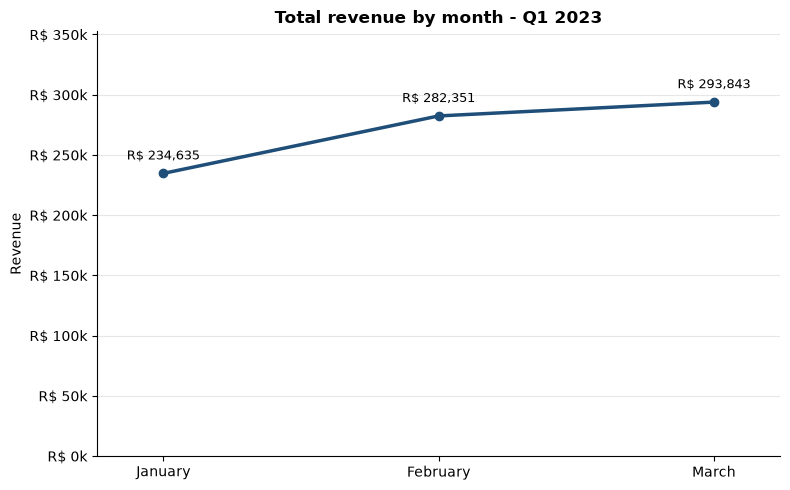

In [24]:
brl_k = FuncFormatter(lambda x, _: f'R$ {x/1000:,.0f}k')
COLOR = '#1f4e79'

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(by_month['month_name'], by_month['revenue'], marker='o', lw=2.5, color=COLOR)
for x, y in zip(by_month['month_name'], by_month['revenue']):
    ax.annotate(f'R$ {y:,.0f}', (x, y), textcoords='offset points',
                xytext=(0, 10), ha='center', fontsize=9)
ax.set_title('Total revenue by month - Q1 2023', fontweight='bold')
ax.set_ylabel('Revenue')
ax.yaxis.set_major_formatter(brl_k)
ax.set_ylim(0, by_month['revenue'].max() * 1.2)
ax.margins(x=0.12)
ax.grid(axis='y', alpha=.3)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('chart_monthly_revenue.png', dpi=150)
plt.show()



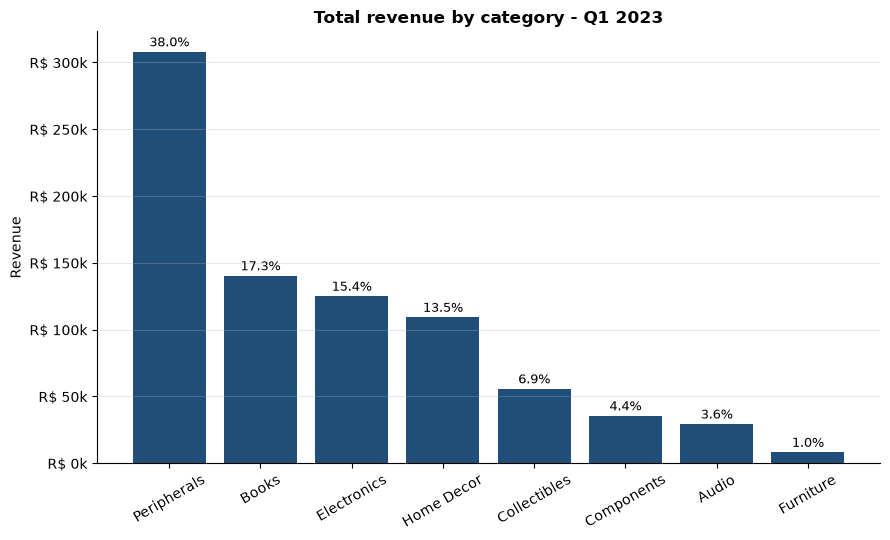

In [25]:
fig, ax = plt.subplots(figsize=(9, 5.5))
bars = ax.bar(by_category['category'], by_category['revenue'], color=COLOR)
for bar, share in zip(bars, by_category['share_%']):
    ax.annotate(f'{share:.1f}%', (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                textcoords='offset points', xytext=(0, 4), ha='center', fontsize=9)
ax.set_title('Total revenue by category - Q1 2023', fontweight='bold')
ax.set_ylabel('Revenue')
ax.yaxis.set_major_formatter(brl_k)
ax.tick_params(axis='x', rotation=30)
ax.grid(axis='y', alpha=.3)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout()
plt.savefig('chart_category_revenue.png', dpi=150)
plt.show()

In [27]:
comparison = pd.DataFrame({
    'revenue_as_briefed': sales.groupby('category')['revenue'].sum(),
    'revenue_value_as_total': sales.groupby('category')['sale_value'].sum(),
}).sort_values('revenue_as_briefed', ascending=False)
comparison['rank_as_briefed'] = comparison['revenue_as_briefed'].rank(ascending=False).astype(int)
comparison['rank_value_as_total'] = comparison['revenue_value_as_total'].rank(ascending=False).astype(int)
print('\nSensitivity check:\n', comparison.round(0).to_string())
 


Sensitivity check:
               revenue_as_briefed  revenue_value_as_total  rank_as_briefed  rank_value_as_total
category                                                                                      
Peripherals             307922.0                123534.0                1                    1
Books                   140286.0                 53787.0                2                    2
Electronics             124974.0                 43281.0                3                    3
Home Decor              109156.0                 40241.0                4                    4
Collectibles             55658.0                 26358.0                5                    5
Components               35468.0                 20338.0                6                    6
Audio                    29281.0                 16362.0                7                    7
Furniture                 8083.0                  5196.0                8                    8
